In [1]:
import os

import pandas as pd
import numpy as np
import xarray as xr

import matplotlib.pyplot as plt

from bluemath_tk.core.io import load_model
from tv_var.harmonic_standardizer import HarmonicStandardizer

In [2]:
models_dict = {
    'ALR + KDE'                  : 'alr_kde.nc',
    'ALR + KDE filter'           : 'alr_kde_filter.nc',
    'VAR RAW EXOG'               :'var_raw_exog.nc',
    'VAR ZS_H3'                  :'var_zs_nh_3.nc',
    'VAR ZS_H3 MR'               :'var_zs_nh_3_monthly_resid.nc',
    'VAR SEASONAL'               :'var_seasonal_zs_nh_3.nc',
    'VAR ZS_H3 PERIODIC H1'      :'var_periodic_zs_nh_3_eh_1.nc',
    'VAR ZS_H3 PERIODIC H2'      :'var_periodic_zs_nh_3_eh_2.nc',
}

path_outputs = '/lustre/geocean/WORK/users/alonsoap/projects/TWINPEACS/02_Emulator_Testing/wt_var_testing/outputs/model_comp'

kma_ob = load_model('/lustre/geocean/WORK/users/alonsoap/projects/TWINPEACS/02_Emulator_Testing/wt_var_testing/outputs/alr/classifier.pkl')

era5_data = pd.read_csv('/lustre/geocean/WORK/users/alonsoap/projects/TWINPEACS/02_Emulator_Testing/wt_var_testing/inputs/pcs_df.csv', index_col=0, parse_dates=True)

In [3]:
models_dict.keys()

dict_keys(['ALR + KDE', 'ALR + KDE filter', 'VAR RAW EXOG', 'VAR ZS_H3', 'VAR ZS_H3 MR', 'VAR SEASONAL', 'VAR ZS_H3 PERIODIC H1', 'VAR ZS_H3 PERIODIC H2'])

In [4]:
sims = {}
pc_names = ['PC1','PC2','PC3','PC4','PC5','PC6']

def classify(values):
    """PC array (n, 6) -> weather type, 1..N_TYPES (ids 0-35 shifted by +1)."""
    pred, _ = kma_ob.predict(pd.DataFrame(values, columns=pc_names))
    return pred.kma_bmus.values + 1

for model, fname in models_dict.items():
    ds = xr.open_dataset(os.path.join(path_outputs, fname))
    ds = ds.transpose("seed", "time", "pc")

    v = ds["pcs"].sel(pc=pc_names).values
    n_s, n_t, n_p = v.shape
    ds["wt"] = (("seed", "time"), classify(v.reshape(-1, n_p)).reshape(n_s, n_t))
    sims[model] = ds

In [5]:
# 1. the filtered ALR must reclassify exactly into its own types
f = sims["ALR + KDE filter"]
print("filter consistency:", (f["wt"].values == f["bmus"].values + 1).mean())      # 1.0

# 2. unfiltered: should give back your 71.6%
a = sims["ALR + KDE"]
print("ALR+KDE consistency:", (a["wt"].values == a["bmus"].values + 1).mean())

filter consistency: 1.0
ALR+KDE consistency: 0.7158696544106044


#### Monthly Mean And Variance

In [6]:
monthly_means = era5_data.groupby(era5_data.index.month).mean()
monthly_std   = era5_data.groupby(era5_data.index.month).std()

sim_means, sim_stds = {}, {}
for model in models_dict:
    data = sims[model]
    means, stds = [], []
    for s in data.seed.values:
        df = data.sel(seed=s).pcs.to_pandas()
        means.append(df.groupby(df.index.month).mean().values)     # (12, 6)
        stds.append(df.groupby(df.index.month).std().values)
    sim_means[model] = np.stack(means)                             # (100, 12, 6)
    sim_stds[model]  = np.stack(stds)

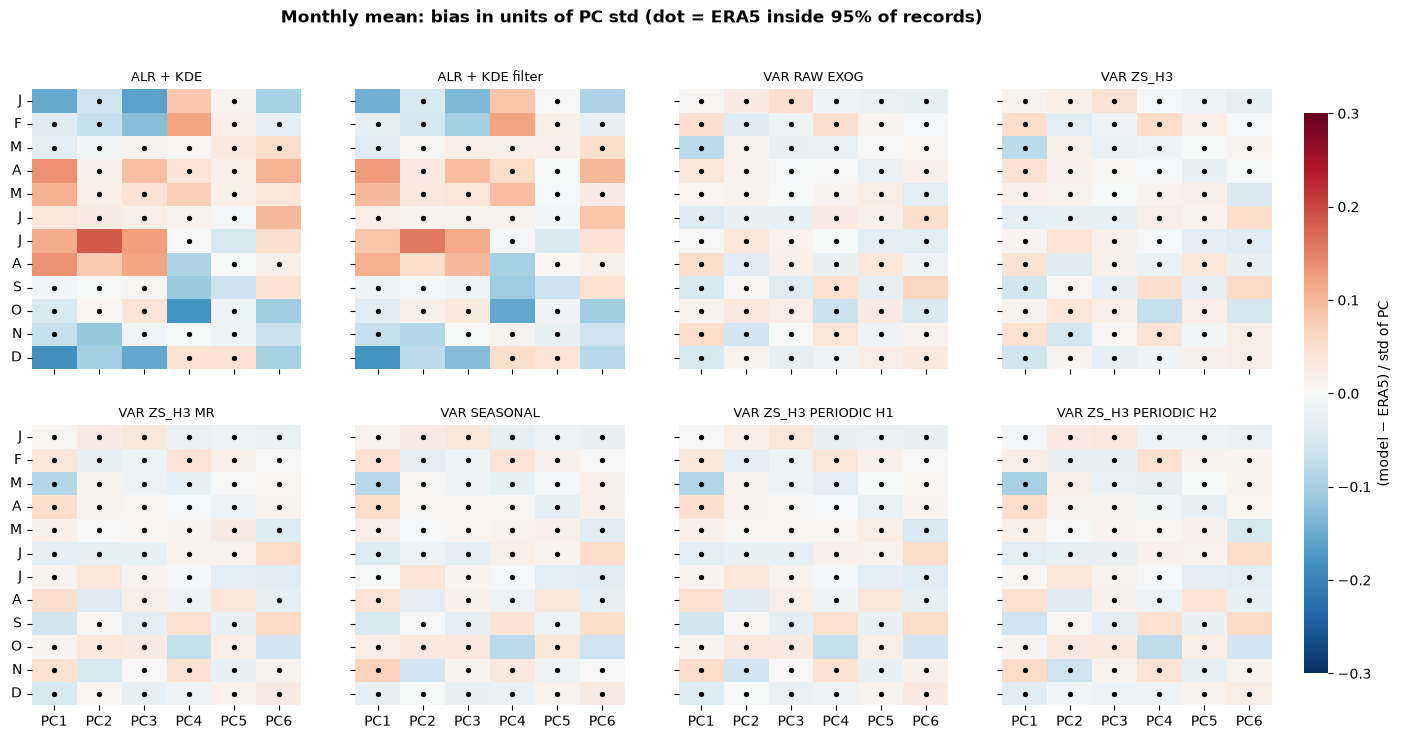

In [7]:
import seaborn as sns

pc_std = era5_data[pc_names].std()

fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharex=True, sharey=True)
cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])           # one shared colorbar on the right

for i, (ax, model) in enumerate(zip(axes.flat, models_dict)):
    error = (np.median(sim_means[model], axis=0) - monthly_means) / pc_std
    sns.heatmap(error, ax=ax, cmap="RdBu_r", center=0, vmin=-0.3, vmax=0.3,
                cbar=(i == 0), cbar_ax=cbar_ax if i == 0 else None,
                cbar_kws={"label": "(model − ERA5) / std of PC"})

    # black dot: ERA5 inside the 2.5–97.5% range of the records
    lo, hi = np.percentile(sim_means[model], [2.5, 97.5], axis=0)
    r, c = np.nonzero((monthly_means.values >= lo) & (monthly_means.values <= hi))
    ax.scatter(c + 0.5, r + 0.5, s=8, color="black")

    ax.set_title(model, fontsize=9)
    ax.set_xlabel(""); ax.set_ylabel("")

axes[0, 0].set_yticklabels(list("JFMAMJJASOND"), rotation=0)
axes[1, 0].set_yticklabels(list("JFMAMJJASOND"), rotation=0)
fig.suptitle("Monthly mean: bias in units of PC std (dot = ERA5 inside 95% of records)", fontweight="bold")
fig.subplots_adjust(right=0.9)
plt.show()

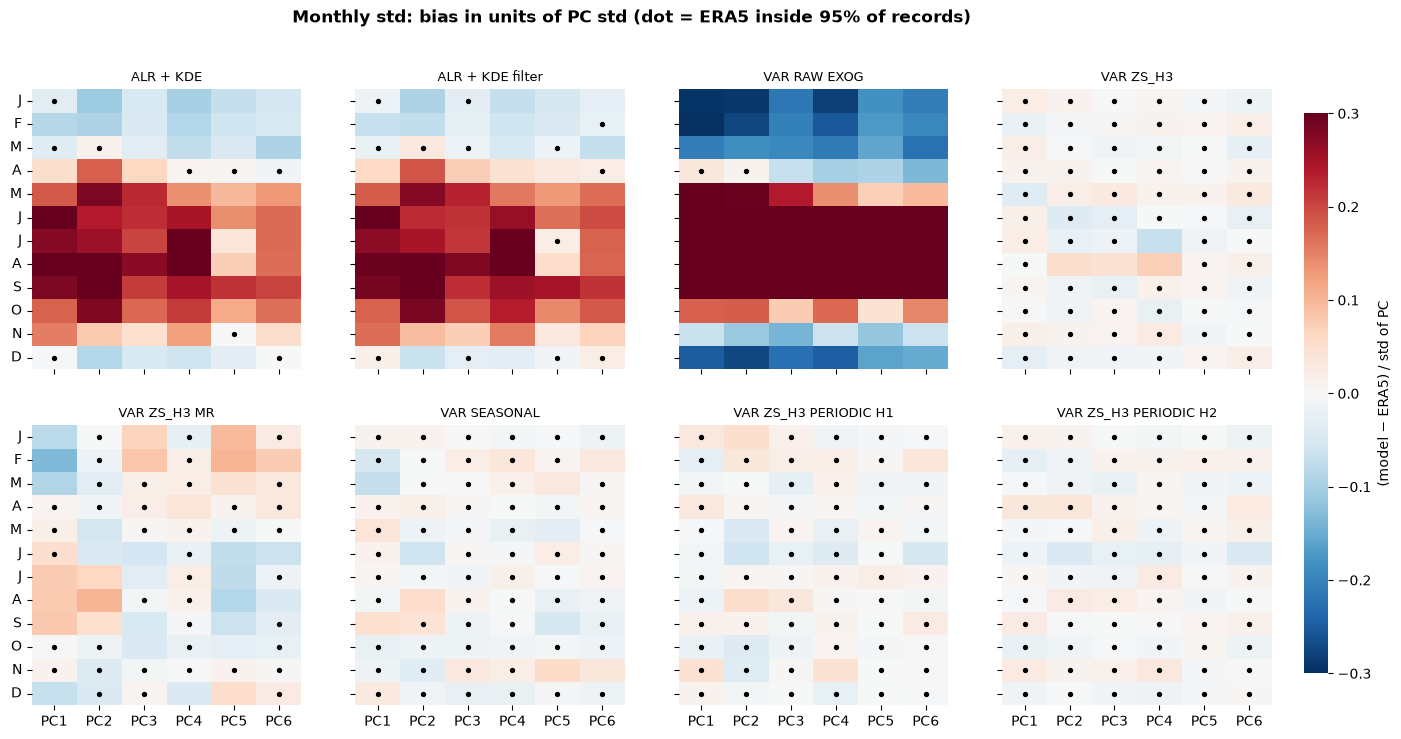

In [8]:
import seaborn as sns

pc_std = era5_data[pc_names].std()

fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharex=True, sharey=True)
cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])           # one shared colorbar on the right

for i, (ax, model) in enumerate(zip(axes.flat, models_dict)):
    error = np.median(sim_stds[model], axis=0) / monthly_std - 1 
    sns.heatmap(error, ax=ax, cmap="RdBu_r", center=0, vmin=-0.3, vmax=0.3,
                cbar=(i == 0), cbar_ax=cbar_ax if i == 0 else None,
                cbar_kws={"label": "(model − ERA5) / std of PC"})

    # black dot: ERA5 inside the 2.5–97.5% range of the records
    lo, hi = np.percentile(sim_stds[model], [2.5, 97.5], axis=0)
    r, c = np.nonzero((monthly_std.values >= lo) & (monthly_std.values <= hi))
    ax.scatter(c + 0.5, r + 0.5, s=8, color="black")

    ax.set_title(model, fontsize=9)
    ax.set_xlabel(""); ax.set_ylabel("")

axes[0, 0].set_yticklabels(list("JFMAMJJASOND"), rotation=0)
axes[1, 0].set_yticklabels(list("JFMAMJJASOND"), rotation=0)
fig.suptitle("Monthly std: bias in units of PC std (dot = ERA5 inside 95% of records)", fontweight="bold")
fig.subplots_adjust(right=0.9)
plt.show()

#### Autocorrelations

In [9]:
MAX_LAG = 10
lags = np.arange(MAX_LAG + 1)

def acf_by_month(df, max_lag=10):
    """{f'{pc}_month_{m}': [1, r1, ..., r_max_lag]} on the given (standardized) data."""
    auto_corr = {}
    for pc in df.columns:
        era5_aux_df = df[[pc]].copy()
        for i in range(1, max_lag + 1):
            era5_aux_df[f'{pc}_lag_{i}'] = era5_aux_df[pc].shift(i)

        era5_aux_df['month'] = era5_aux_df.index.month
        for month in range(1, 13):
            aux_df = era5_aux_df[era5_aux_df['month'] == month].drop(columns='month')
            auto_corr[f'{pc}_month_{month}'] = aux_df.corr().values[:, 0]
    return auto_corr

harm_std = HarmonicStandardizer(n_harmonics=3).fit(era5_data[pc_names])

def acf_array(df):
    d = acf_by_month(df, max_lag=MAX_LAG)
    return np.array([[d[f"{pc}_month_{m}"] for pc in pc_names] for m in range(1, 13)])   # (12, 6, MAX_LAG+1)

obs_acf = acf_array(harm_std.transform(era5_data[pc_names]))                                # (12, 6, 11)

sim_acf = {}
for model in models_dict:
    data = sims[model]
    sim_acf[model] = np.stack([acf_array(harm_std.transform(data.sel(seed=s).pcs.to_pandas()))
                               for s in data.seed.values])                                   # (100, 12, 6, 11)
    print(model, "done")

def plot_acf_matrix(model):
    arr = sim_acf[model]                                           # (100, 12, 6, lags)
    lo, med, hi = np.percentile(arr, [5, 50, 95], axis=0)

    fig, axes = plt.subplots(12, 6, figsize=(12, 18), sharex=True, sharey=True)
    for m in range(12):
        for j, pc in enumerate(pc_names):
            ax = axes[m, j]
            ax.fill_between(lags, lo[m, j], hi[m, j], color="#2a78d6", alpha=0.3, lw=0)
            ax.plot(lags, med[m, j], color="#2a78d6", lw=1)
            ax.plot(lags, obs_acf[m, j], color="black", lw=1.2)
            ax.set_ylim(-0.2, 1)
            if m == 0:  ax.set_title(pc)
            if j == 0:  ax.set_ylabel("JFMAMJJASOND"[m], rotation=0, labelpad=10)
    fig.suptitle(f"{model}: ACF by month (black ERA5, blue median and 5–95%)", fontweight="bold")
    fig.tight_layout(); plt.show()

fig_dir = "../outputs/figures/acf"
os.makedirs(fig_dir, exist_ok=True)

lags   = np.arange(MAX_LAG + 1)
models = list(models_dict)
months = "JFMAMJJASOND"

for j, pc in enumerate(pc_names):
    fig, axes = plt.subplots(12, len(models), figsize=(2 * len(models), 18), sharex=True, sharey=True)

    for k, model in enumerate(models):
        lo, med, hi = np.percentile(sim_acf[model][:, :, j], [5, 50, 95], axis=0)   # (12, lags)
        for m in range(12):
            ax = axes[m, k]
            ax.fill_between(lags, lo[m], hi[m], color="#2a78d6", alpha=0.3, lw=0)
            ax.plot(lags, med[m], color="#2a78d6", lw=1)
            ax.plot(lags, obs_acf[m, j], color="black", lw=1.2)
            ax.set_ylim(-0.2, 1)
            if m == 0: ax.set_title(model, fontsize=8)
            if k == 0: ax.set_ylabel(months[m], rotation=0, labelpad=10)

    fig.suptitle(f"{pc}: ACF by month (black ERA5, blue median and 5–95%)", fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.98])
    fig.savefig(f"{fig_dir}/acf_{pc}.png", dpi=150)
    plt.close(fig)
    print("saved", f"{fig_dir}/acf_{pc}.png")

ALR + KDE done
ALR + KDE filter done
VAR RAW EXOG done
VAR ZS_H3 done
VAR ZS_H3 MR done
VAR SEASONAL done
VAR ZS_H3 PERIODIC H1 done
VAR ZS_H3 PERIODIC H2 done
saved ../outputs/figures/acf/acf_PC1.png
saved ../outputs/figures/acf/acf_PC2.png
saved ../outputs/figures/acf/acf_PC3.png
saved ../outputs/figures/acf/acf_PC4.png
saved ../outputs/figures/acf/acf_PC5.png
saved ../outputs/figures/acf/acf_PC6.png


In [11]:
def corr_by_month(z):
    return np.stack([z[z.index.month == m].corr().values for m in range(1, 13)])     # (12, 6, 6)

z_era5 = harm_std.transform(era5_data)
obs_corr0 = corr_by_month(z_era5)

sim_corr0 = {}
for model in models_dict:
    data = sims[model]
    sim_corr0[model] = np.stack([corr_by_month(harm_std.transform(data.sel(seed=s).pcs.to_pandas()))
                                 for s in data.seed.values])                       # (100, 12, 6, 6)

models = list(models_dict)
fig, axes = plt.subplots(12, len(models) + 1, figsize=(2.2 * (len(models) + 1), 26))

for m in range(12):
    # ERA5
    sns.heatmap(obs_corr0[m], ax=axes[m, 0], cmap="RdBu_r", vmin=-0.5, vmax=0.5, center=0, cbar=False)
    axes[m, 0].set_ylabel("JFMAMJJASOND"[m], rotation=0, labelpad=10)

    # models: median − ERA5, dot if ERA5 inside 95% of records
    for k, model in enumerate(models, start=1):
        arr = sim_corr0[model][:, m]                                               # (100, 6, 6)
        sns.heatmap(np.median(arr, 0) - obs_corr0[m], ax=axes[m, k],
                    cmap="RdBu_r", vmin=-0.3, vmax=0.3, center=0, cbar=False)
        lo, hi = np.percentile(arr, [2.5, 97.5], axis=0)
        r, c = np.nonzero((obs_corr0[m] >= lo) & (obs_corr0[m] <= hi))
        axes[m, k].scatter(c + 0.5, r + 0.5, s=4, color="black")

axes[0, 0].set_title("ERA5", fontsize=9)
for k, model in enumerate(models, start=1):
    axes[0, k].set_title(model, fontsize=8)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])

fig.subplots_adjust(left=0.03, right=0.99, top=0.96, bottom=0.06, wspace=0.08, hspace=0.08)

cax1 = fig.add_axes([0.03, 0.025, 0.09, 0.006])          # under the ERA5 column
cax2 = fig.add_axes([0.40, 0.025, 0.30, 0.006])          # under the model columns
fig.colorbar(axes[0, 0].collections[0], cax=cax1, orientation="horizontal", label="ERA5 correlation")
fig.colorbar(axes[0, 1].collections[0], cax=cax2, orientation="horizontal", label="model − ERA5")

fig.savefig(f"{fig_dir}/corr_lag0.png", dpi=150); plt.close(fig)

In [12]:
def corr_lag_by_month(z, lag):
    """(12, 6, 6): cell [m, i, j] = corr(PC_i at t, PC_j at t+lag), for t in month m+1."""
    future = z.shift(-lag)
    out = np.empty((12, 6, 6))
    for m in range(1, 13):
        sel = (z.index.month == m) & future.notna().all(axis=1).values
        a, b = z.values[sel], future.values[sel]
        out[m - 1] = np.corrcoef(a.T, b.T)[:6, 6:]        # today × later block
    return out

LAGS_X = [1, 2, 3]
obs_corr = {L: corr_lag_by_month(z_era5, L) for L in LAGS_X}

sim_corr = {L: {} for L in LAGS_X}
for model in models_dict:
    data = sims[model]
    recs = [harm_std.transform(data.sel(seed=s).pcs.to_pandas()) for s in data.seed.values]
    for L in LAGS_X:
        sim_corr[L][model] = np.stack([corr_lag_by_month(r, L) for r in recs])   # (100, 12, 6, 6)
    print(model, "done")

ALR + KDE done
ALR + KDE filter done
VAR RAW EXOG done
VAR ZS_H3 done
VAR ZS_H3 MR done
VAR SEASONAL done
VAR ZS_H3 PERIODIC H1 done
VAR ZS_H3 PERIODIC H2 done


In [13]:
models = list(models_dict)

for L in LAGS_X:
    fig, axes = plt.subplots(12, len(models) + 1, figsize=(2.2 * (len(models) + 1), 26))

    for m in range(12):
        # ERA5: correlation itself
        sns.heatmap(obs_corr[L][m], ax=axes[m, 0], cmap="RdBu_r", vmin=-0.5, vmax=0.5, center=0, cbar=False)
        axes[m, 0].set_ylabel("JFMAMJJASOND"[m], rotation=0, labelpad=10)

        # models: median − ERA5, dot if ERA5 inside 95% of records
        for k, model in enumerate(models, start=1):
            arr = sim_corr[L][model][:, m]                                  # (100, 6, 6)
            sns.heatmap(np.median(arr, 0) - obs_corr[L][m], ax=axes[m, k],
                        cmap="RdBu_r", vmin=-0.3, vmax=0.3, center=0, cbar=False)
            lo, hi = np.percentile(arr, [2.5, 97.5], axis=0)
            r, c = np.nonzero((obs_corr[L][m] >= lo) & (obs_corr[L][m] <= hi))
            axes[m, k].scatter(c + 0.5, r + 0.5, s=4, color="black")

    axes[0, 0].set_title("ERA5", fontsize=9)
    for k, model in enumerate(models, start=1):
        axes[0, k].set_title(model, fontsize=8)
    for ax in axes.flat:
        ax.set_xticks([]); ax.set_yticks([])

    fig.suptitle(f"Lag-{L} correlation, PC_i today (rows) vs PC_j {L} day(s) later (columns): "
                 "ERA5 (first column), model − ERA5 (others)", fontweight="bold")
    fig.subplots_adjust(left=0.03, right=0.99, top=0.96, bottom=0.06, wspace=0.08, hspace=0.08)

    cax1 = fig.add_axes([0.03, 0.025, 0.09, 0.006])
    cax2 = fig.add_axes([0.40, 0.025, 0.30, 0.006])
    fig.colorbar(axes[0, 0].collections[0], cax=cax1, orientation="horizontal", label="ERA5 correlation")
    fig.colorbar(axes[0, 1].collections[0], cax=cax2, orientation="horizontal", label="model − ERA5")

    fig.savefig(f"{fig_dir}/corr_lag{L}.png", dpi=150); plt.close(fig)
    print("saved", f"{fig_dir}/corr_lag{L}.png")

saved ../outputs/figures/acf/corr_lag1.png
saved ../outputs/figures/acf/corr_lag2.png
saved ../outputs/figures/acf/corr_lag3.png


#### Weather Type frencuency and persistance

In [31]:
kma_era5, _ = kma_ob.predict(era5_data[pc_names])
wt_era5 = kma_era5.kma_bmus.values + 1                                    # 1..36, same as sims

N_TYPES = 36
obs_freq = np.bincount(wt_era5, minlength=N_TYPES + 1)[1:] / len(wt_era5)   # (36,)

sim_freq = {}
for model in models:
    wt = sims[model].wt.values                                             # (100, n_days)
    sim_freq[model] = np.stack([np.bincount(rec, minlength=N_TYPES + 1)[1:] / len(rec) for rec in wt])   # (100, 36)

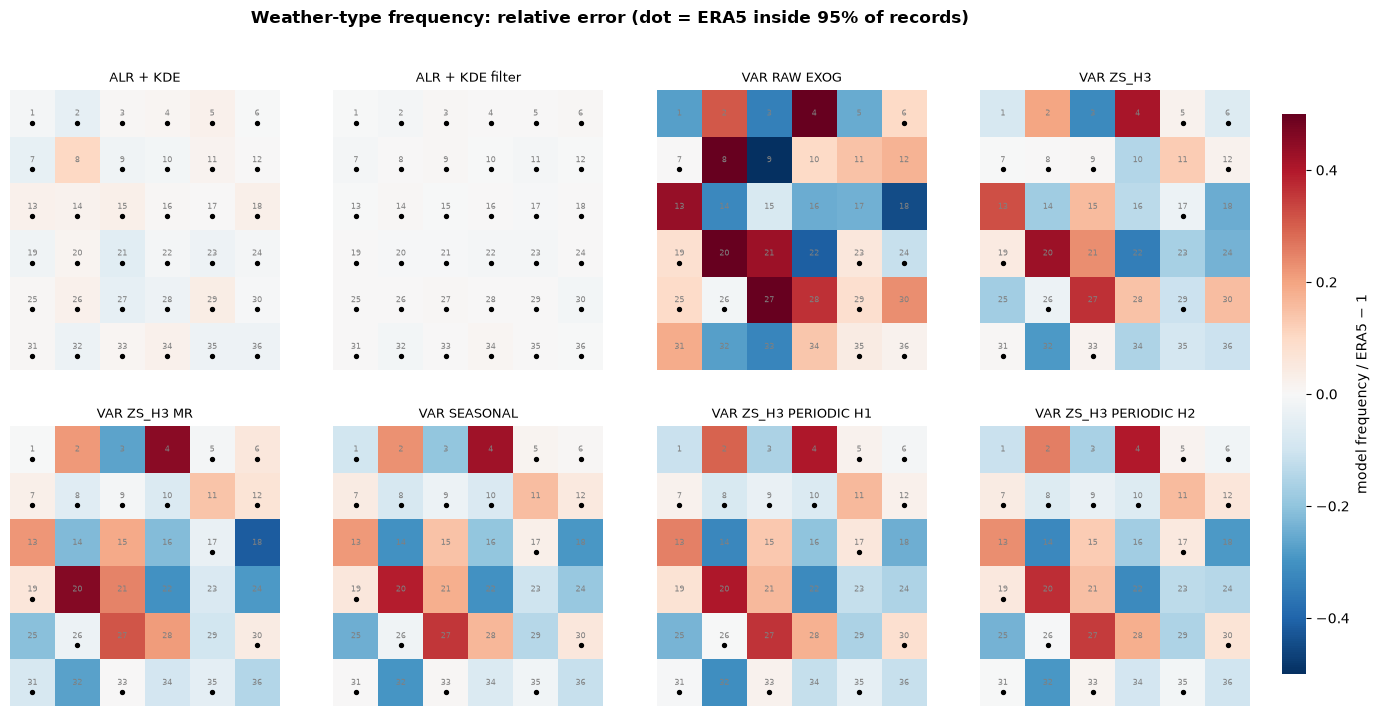

In [32]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharex=True, sharey=True)
cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])

for i, (ax, model) in enumerate(zip(axes.flat, models)):
    arr   = sim_freq[model]                                       # (100, 36)
    error = (np.median(arr, 0) / obs_freq - 1).reshape(6, 6)

    sns.heatmap(error, ax=ax, cmap="RdBu_r", center=0, vmin=-0.5, vmax=0.5,
                annot=np.arange(1, 37).reshape(6, 6), fmt="d", annot_kws={"fontsize": 6, "color": "grey"},
                cbar=(i == 0), cbar_ax=cbar_ax if i == 0 else None,
                cbar_kws={"label": "model frequency / ERA5 − 1"})

    lo, hi = np.percentile(arr, [2.5, 97.5], axis=0)
    inside = ((obs_freq >= lo) & (obs_freq <= hi)).reshape(6, 6)
    r, c = np.nonzero(inside)
    ax.scatter(c + 0.5, r + 0.7, s=8, color="black")
    ax.set_title(model, fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])

fig.suptitle("Weather-type frequency: relative error (dot = ERA5 inside 95% of records)", fontweight="bold")
fig.subplots_adjust(right=0.9)
plt.show()

In [33]:
def wt_persistence(lab):
    """Mean run length (days) of each type 1..36. NaN if a type never occurs."""
    change   = np.r_[True, lab[1:] != lab[:-1]]          # True where a new run starts
    run_id   = np.cumsum(change)
    lengths  = np.bincount(run_id)[1:]                   # length of each run
    run_type = lab[change]                               # type of each run
    total = np.bincount(run_type, weights=lengths, minlength=N_TYPES + 1)[1:]
    count = np.bincount(run_type, minlength=N_TYPES + 1)[1:]
    with np.errstate(invalid="ignore", divide="ignore"):
        return total / count

obs_pers = wt_persistence(wt_era5)                                                 # (36,)
sim_pers = {m: np.stack([wt_persistence(rec) for rec in sims[m].wt.values]) for m in models}   # (100, 36)

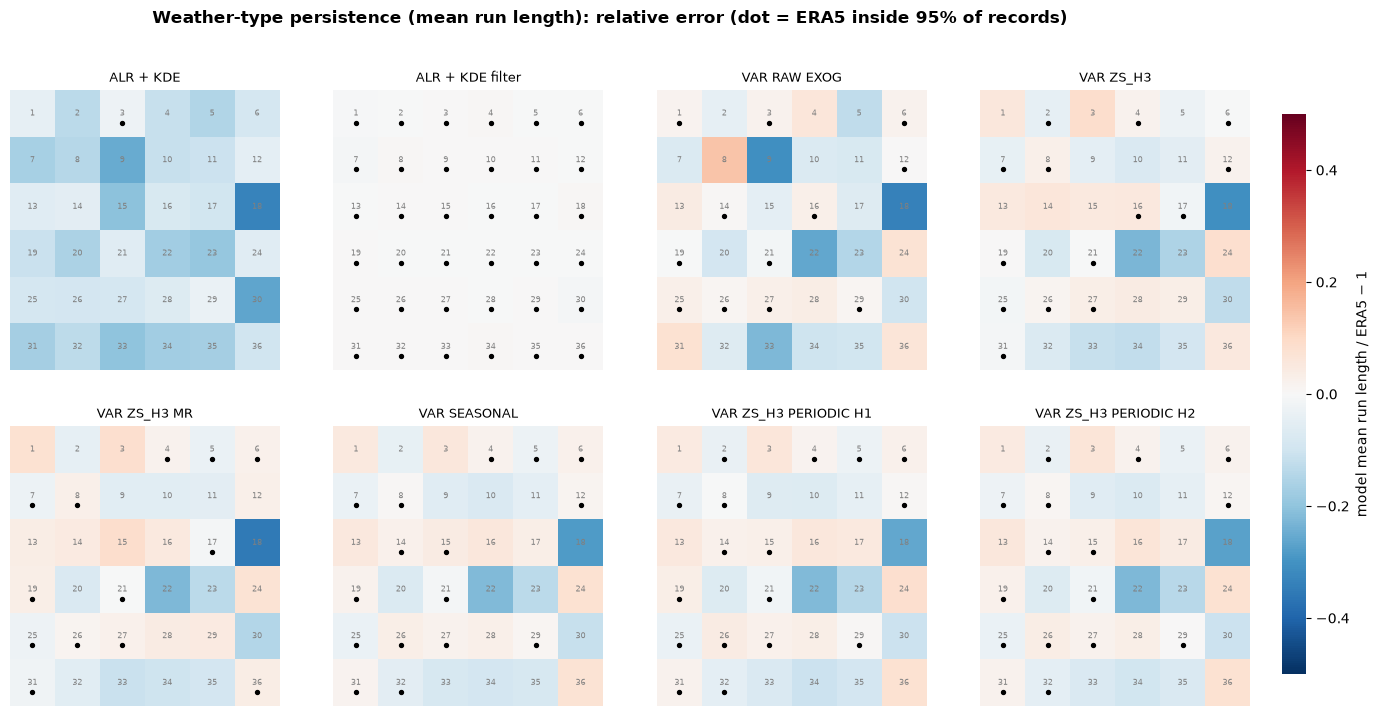

In [34]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharex=True, sharey=True)
cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])

for i, (ax, model) in enumerate(zip(axes.flat, models)):
    arr   = sim_pers[model]                                        # (100, 36)
    error = (np.nanmedian(arr, 0) / obs_pers - 1).reshape(6, 6)

    sns.heatmap(error, ax=ax, cmap="RdBu_r", center=0, vmin=-0.5, vmax=0.5,
                annot=np.arange(1, 37).reshape(6, 6), fmt="d", annot_kws={"fontsize": 6, "color": "grey"},
                cbar=(i == 0), cbar_ax=cbar_ax if i == 0 else None,
                cbar_kws={"label": "model mean run length / ERA5 − 1"})

    lo, hi = np.nanpercentile(arr, [2.5, 97.5], axis=0)
    inside = ((obs_pers >= lo) & (obs_pers <= hi)).reshape(6, 6)
    r, c = np.nonzero(inside)
    ax.scatter(c + 0.5, r + 0.7, s=8, color="black")
    ax.set_title(model, fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])

fig.suptitle("Weather-type persistence (mean run length): relative error (dot = ERA5 inside 95% of records)",
             fontweight="bold")
fig.subplots_adjust(right=0.9)
plt.show()